# Experiment 4 — Forecast Error Analysis Across Epidemic Conditions

sMOA Python: **N=18,387 attempts/family; k=5; m=4,422**. History dùng snapshot JHU trước phát hành; nhãn dùng final truth. Chỉ phân tích sai số của sMOA để rút ra insights; dùng bộ tham số paper đã cố định.

Đọc [README](README.md) cho định nghĩa nhóm, giới hạn và cách chạy. Notebook này đọc các artifact thực tế, không sinh thêm synthetic hoặc chạy lại BO.

Bản audit hiện dùng **bridge=omit** để khớp `full`. Kết quả keep cũ được giữ ở `outputs/experiment_4`; bản mới ở `outputs/experiment_4_omit`. Hình extreme chọn các ca sai lớn nhất, không đại diện toàn bộ dự báo.

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Image, Markdown
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "experiments/error_analysis/conditions.py").exists())
OUT = ROOT / "outputs/experiment_4_omit"
progress = json.loads((OUT / "progress.json").read_text()) if (OUT / "progress.json").exists() else {"status": "not_started"}
display(progress)
if progress["status"] != "complete":
    raise RuntimeError("Run chưa hoàn tất. Xem outputs/experiment_4_omit/progress.json và README trước khi chấm kết quả.")

{'status': 'complete',
 'started_utc': '2026-10-30T19:55:51.902151+00:00',
 'completed_cases': 2500,
 'total_cases': 2500,
 'output_dir': '/Users/nguyentranglinh/infectious-disease-forecasting/outputs/experiment_4_omit',
 'last_origin': '2022-10-01',
 'failed_cases': 0,
 'finished_utc': '2026-10-30T19:56:46.100840+00:00',
 'setup_seconds': 11.437817209167406,
 'forecast_count': 10000,
 'artifacts': ['instances.csv',
  'case_status.csv',
  'overall.csv',
  'report.md',
  'figures/']}

In [2]:
protocol = json.loads((OUT / "protocol.json").read_text())
display(protocol["rules"])
display(pd.read_csv(OUT / "overall.csv"))
for dimension in ["phase", "case_level", "volatility_level", "history_stage"]:
    display(Markdown("### " + dimension))
    display(pd.read_csv(OUT / f"group_counts_{dimension}.csv"))

{'version': 3,
 'phase': '(mean(last 2)+1)/(mean(previous 2)+1)-1: rising >0.10, declining <-0.10, stable otherwise',
 'case_level': 'mean(last 4): low <1000, medium [1000,10000), high >=10000 weekly state cases',
 'volatility': 'sample SD of differences of log1p(last 8 weekly counts): low <0.15, medium [0.15,0.40), high >=0.40',
 'history_stage': 'early <=26 observed weekly values; later >26 (full available history, no artificial truncation)',
 'normalization': 'max(mean(last 4 origin-available model-input weekly counts),1)',
 'extreme_error': 'absolute error / origin normalization >1; sensitivity >0.5 and >2',
 'bias': 'prediction minus final raw truth: negative means underprediction',
 'history_preprocessing': 'floor raw weekly counts at 1, exactly as the sMOA forecast input; retain raw revision flags',
 'horizons': [1, 2, 3, 4],
 'bootstrap': 'state-cluster percentile bootstrap, 1000 replicates, seed 20261030; descriptive, not causal',
 'sampling': 'weekly 2020-04-04..2020-09-05; e

,model,n,states,origins,MAE,RMSE,normalized_MAE,bias,normalized_bias,extreme_rate,...,MAE_lo,MAE_hi,normalized_MAE_lo,normalized_MAE_hi,bias_lo,bias_hi,normalized_bias_lo,normalized_bias_hi,extreme_rate_lo,extreme_rate_hi
0,Original_sMOA_Python,10000,50,50,5310.90755,20620.466661,0.7413,-1122.46885,-0.171099,0.1753,...,3852.166634,7114.34632,0.68529,0.799753,-1927.391445,-484.224611,-0.216585,-0.127458,0.160293,0.18861


### phase

,phase,cases,states,origins
0,rising,1130,50,49
1,stable,465,50,47
2,declining,905,50,46


### case_level

,case_level,cases,states,origins
0,low,506,39,46
1,medium,1344,50,50
2,high,650,46,50


### volatility_level

,volatility_level,cases,states,origins
0,low,472,49,40
1,medium,1375,50,46
2,high,653,50,49


### history_stage

,history_stage,cases,states,origins
0,early,800,50,16
1,later,1700,50,34


Bias âm = dự báo thấp. Normalized absolute error chia cho mean 4 tuần gần origin (floor denominator ở 1). Extreme error >100% mức đó. Các khoảng tin cậy bootstrap theo bang; các nhóm không thể diễn giải như tác động nhân quả.

### Cách đọc các hình prediction

- **Forecast overview:** bốn bang cố định (CA/TX/NY/FL), tất cả origins đã thiết kế; horizon 1/4 vẽ tại target dates. Origins giai đoạn sau cách bốn tuần; đường dự báo nối những điểm thưa.
- **Error quantiles:** ví dụ tại percentile 10/50/90/99 của mean normalized absolute error qua 4 horizons mỗi case. Chọn hậu nghiệm, không phải random sample.
- **Extreme trajectories:** bốn cases có normalized error lớn nhất; dùng để giải thích failure modes, không dùng để mô tả accuracy điển hình. Final history được vẽ cạnh as-of history để thấy revisions, không dùng làm input prediction.

Không thể so pooled MAE của các lịch test khác nhau để kết luận implementation nào tốt hơn. Cell audit dưới cùng đối chiếu đúng cùng state/origin/target.

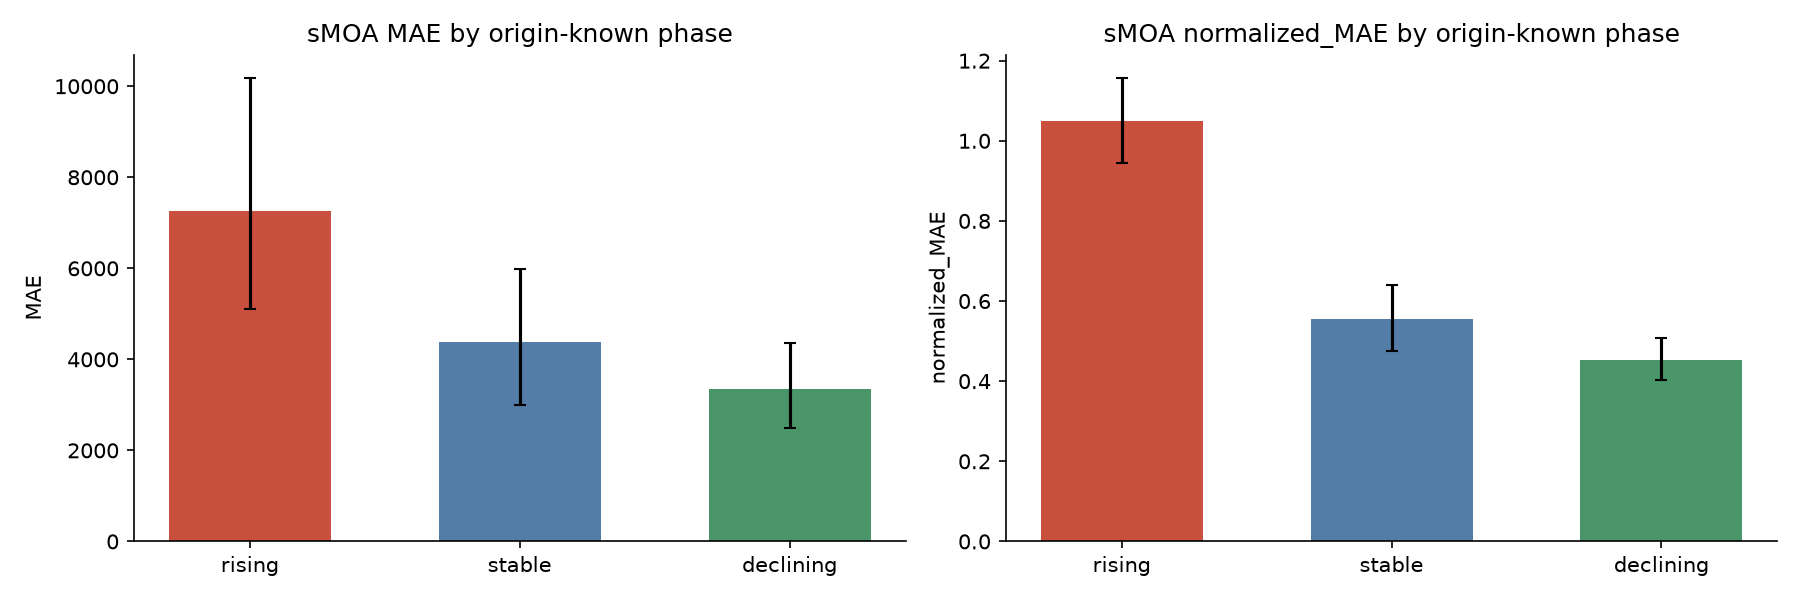

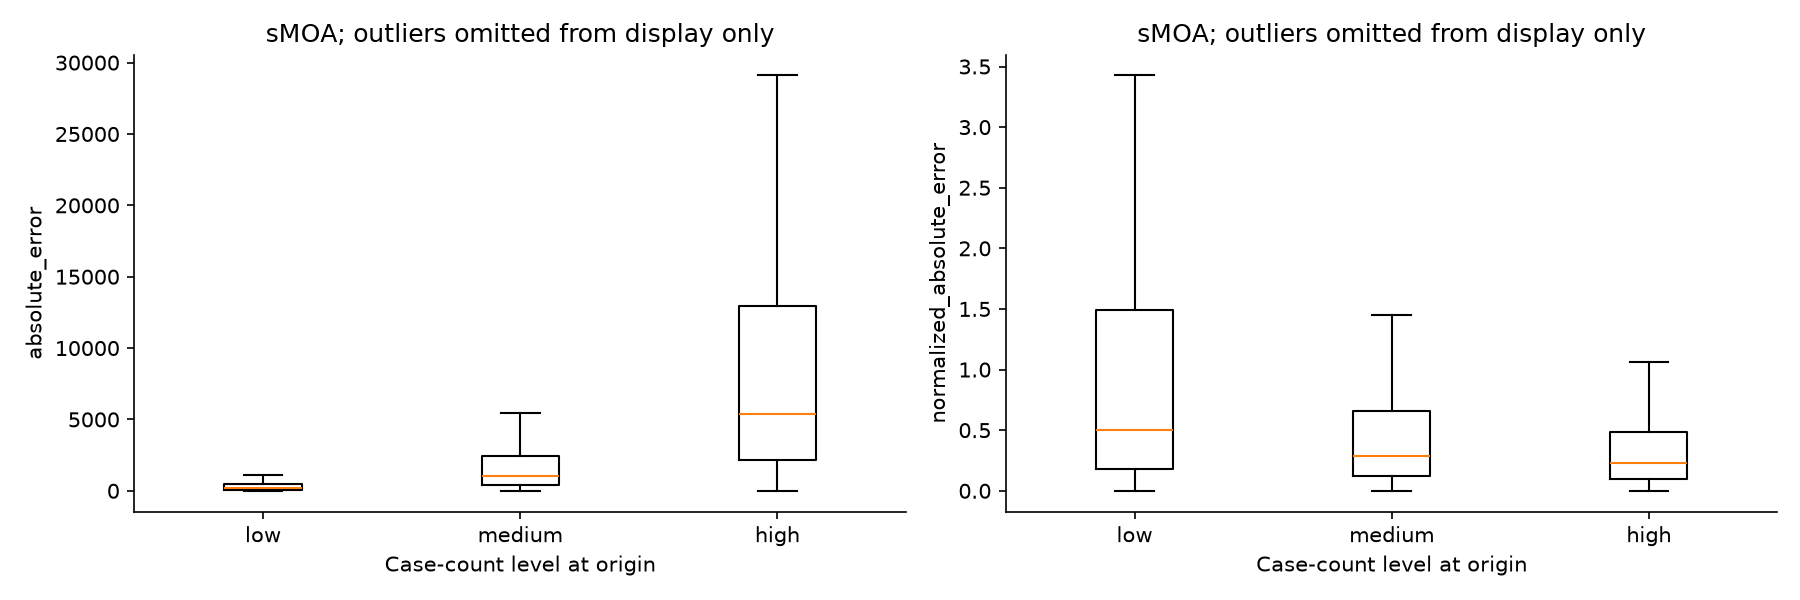

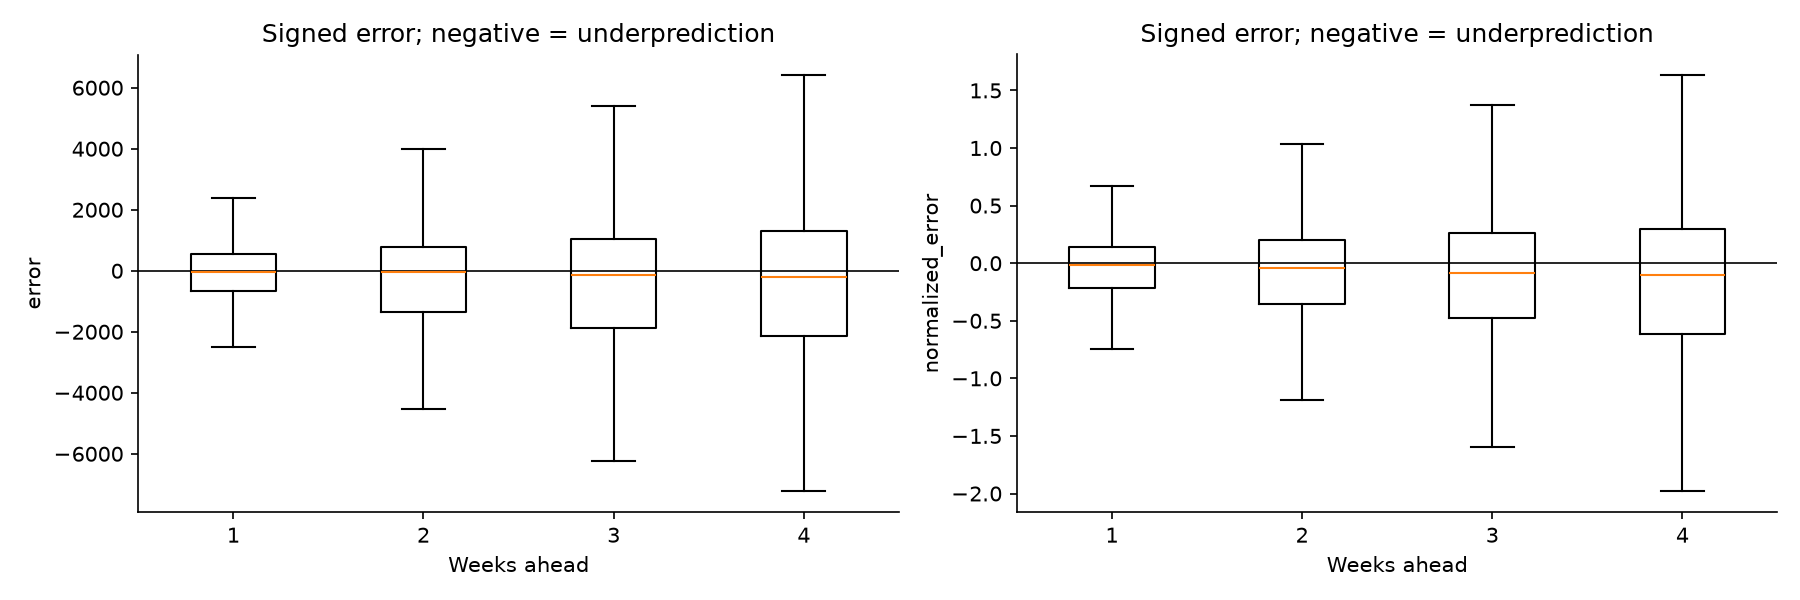

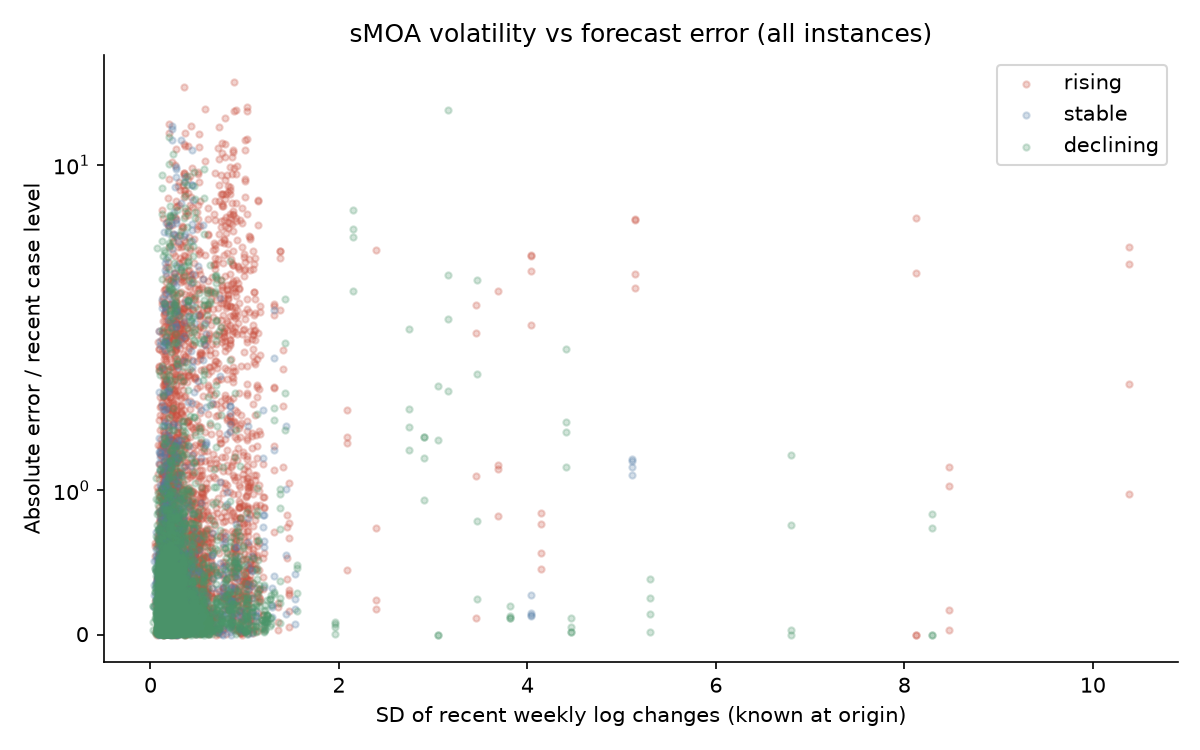

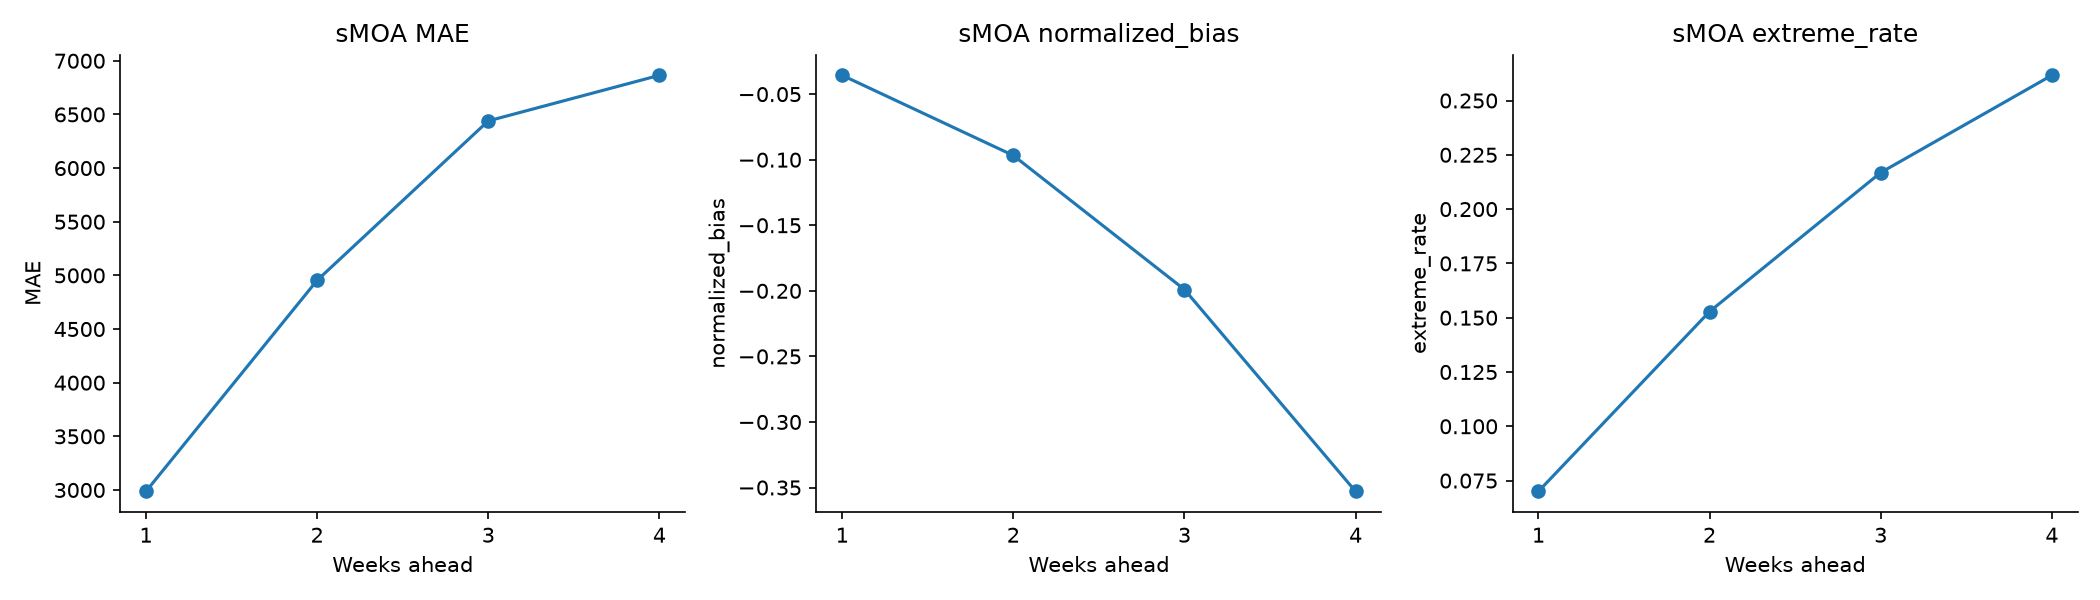

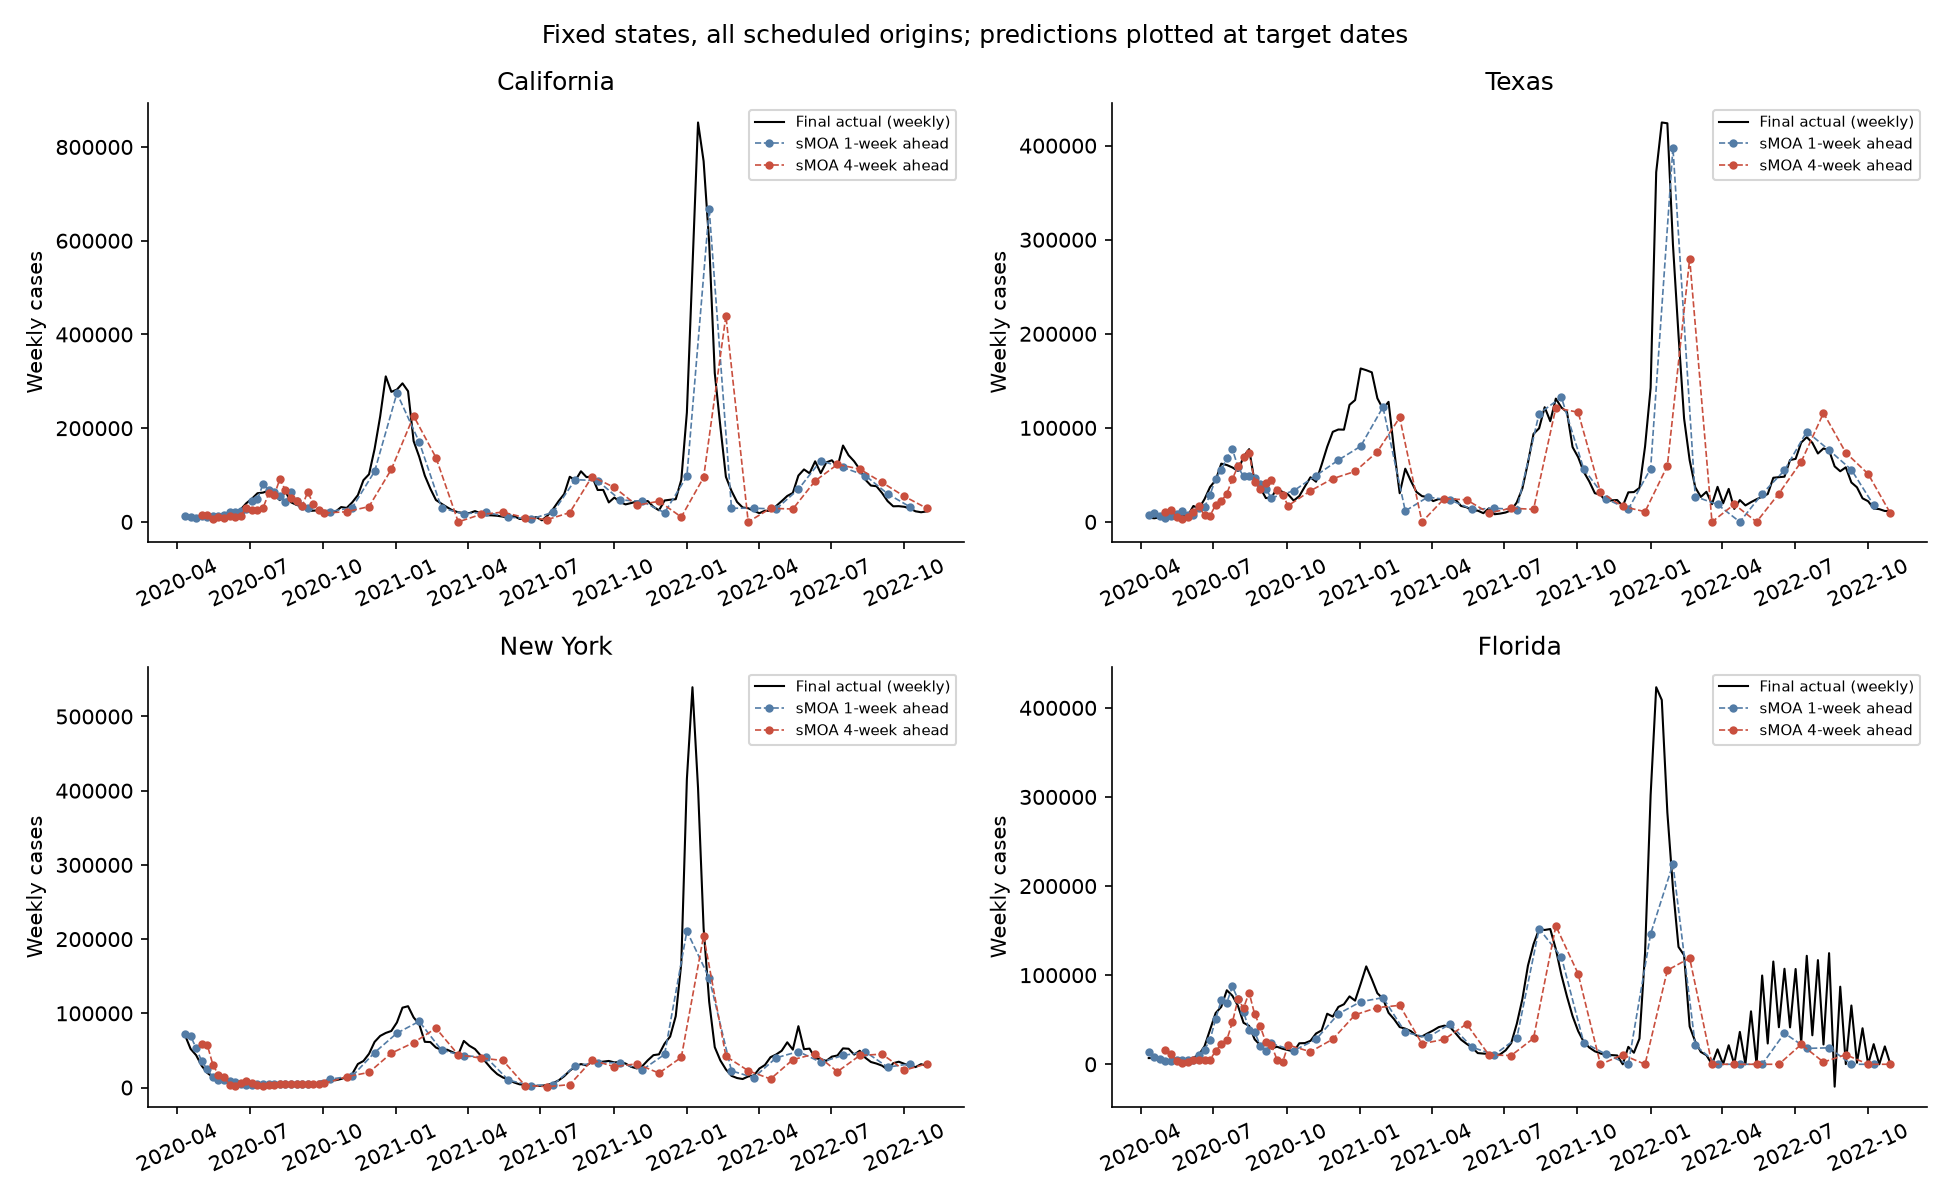

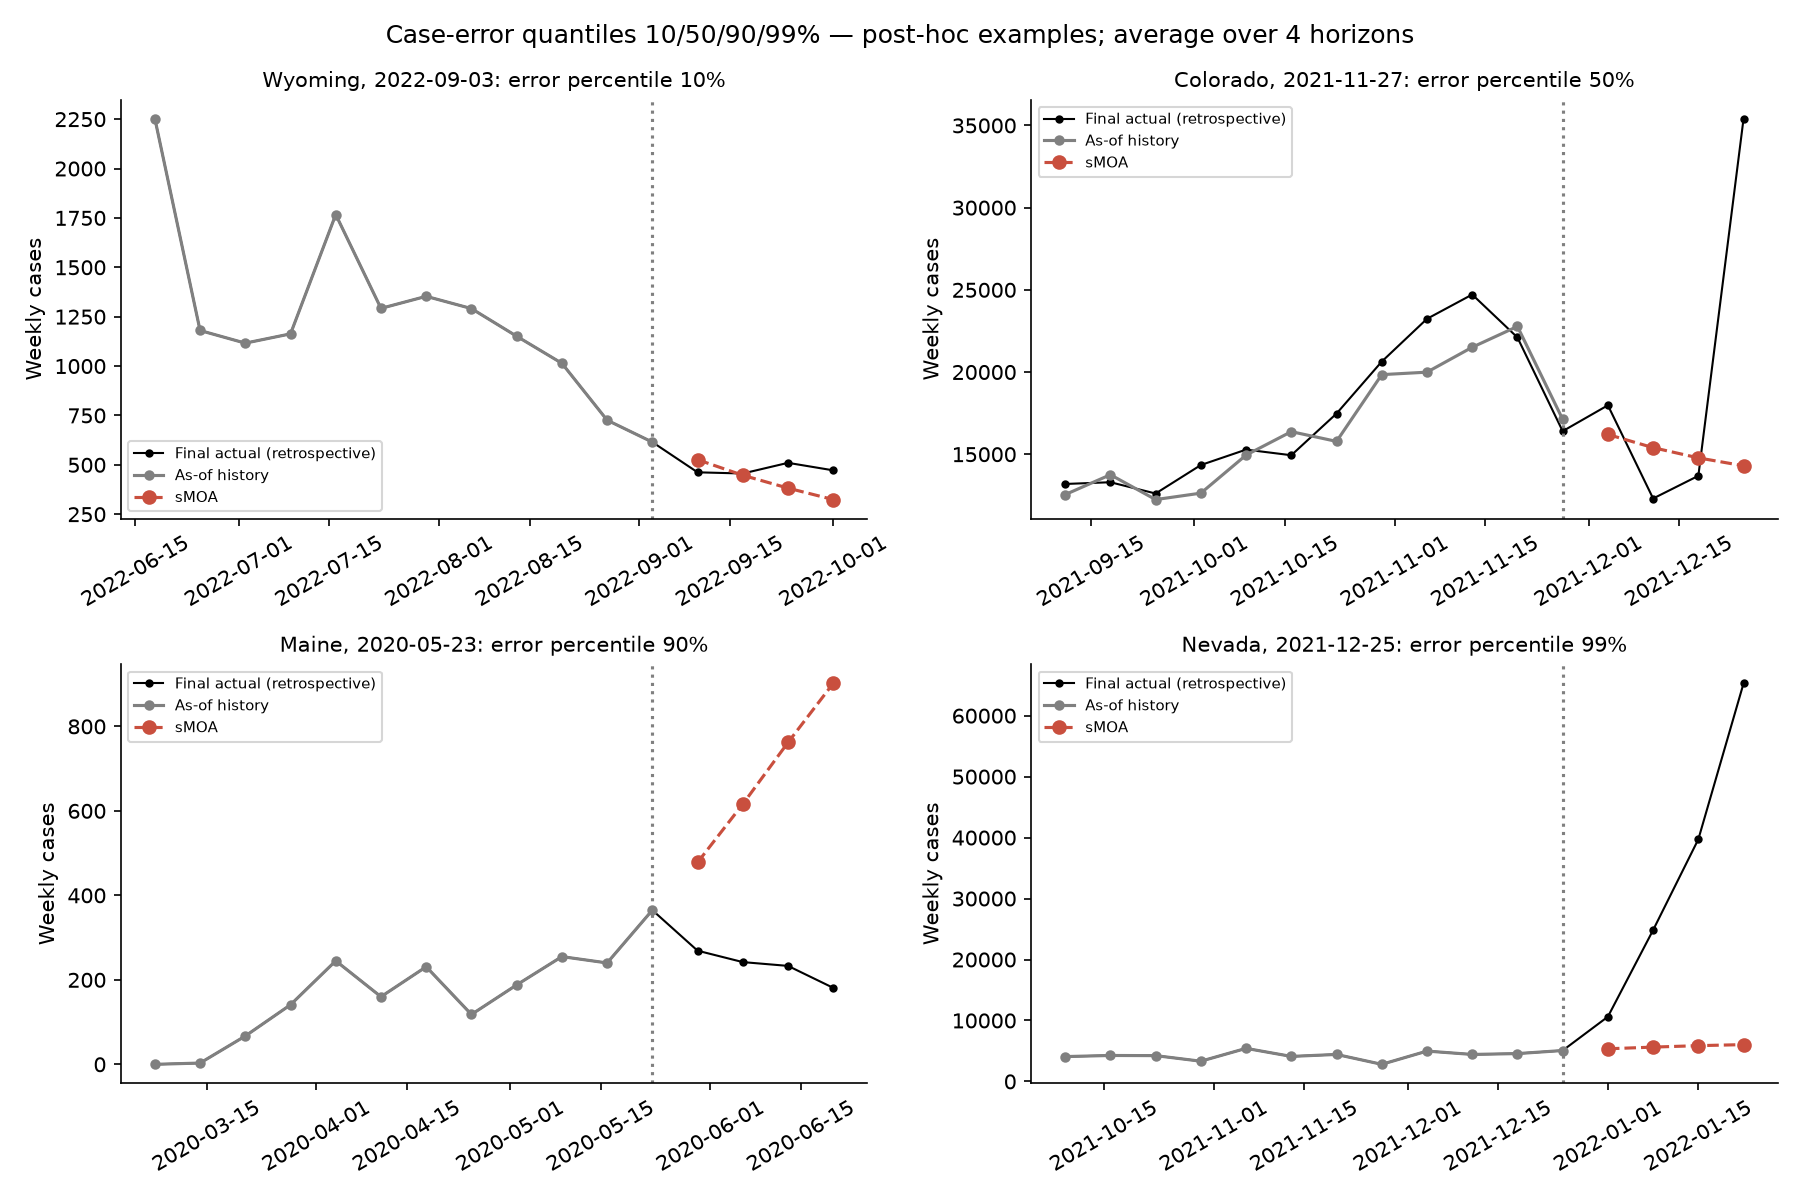

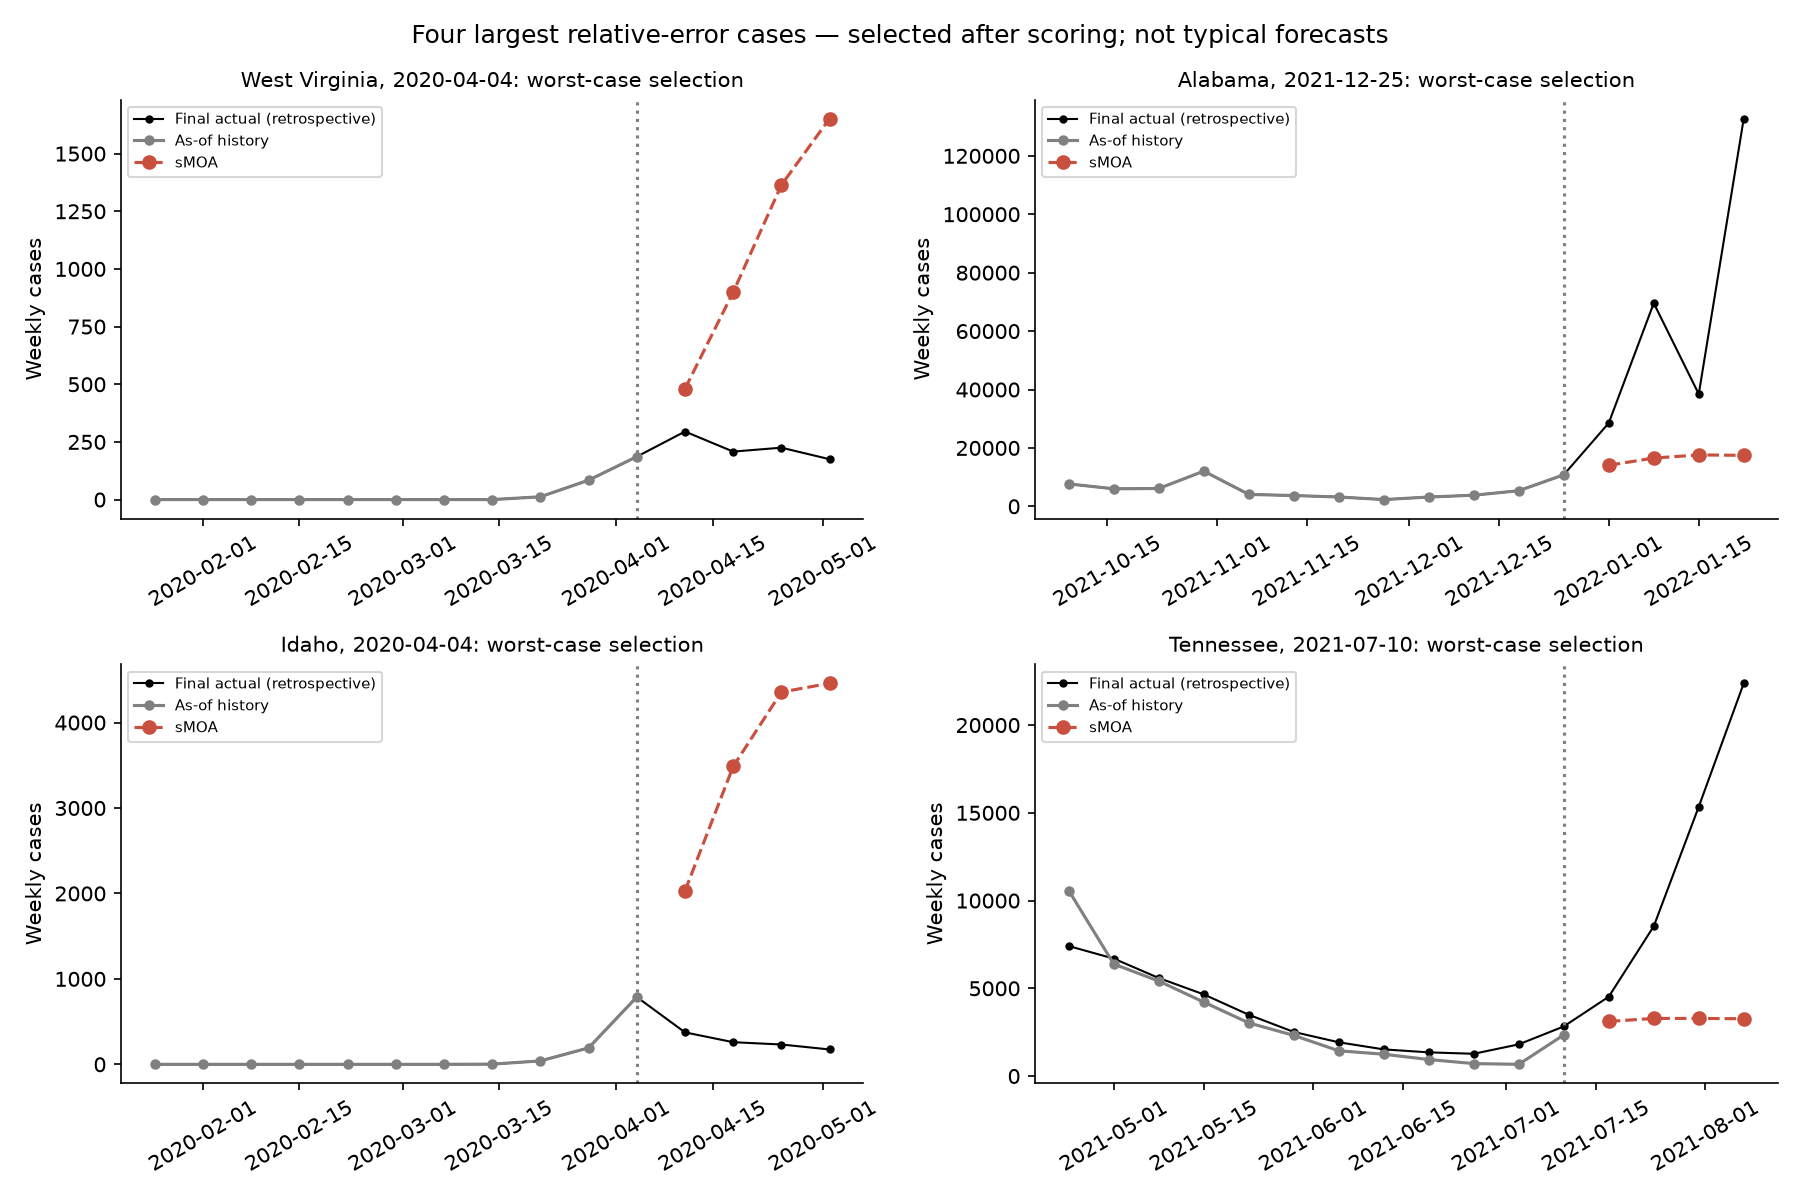

In [3]:
for name in ["phase_mae", "case_count_boxplot", "horizon_distribution", "volatility_scatter", "horizon_metrics", "forecast_overview", "error_quantile_trajectories", "extreme_trajectories"]:
    display(Image(filename=str(OUT / "figures" / f"{name}.png")))

In [4]:
for name in ["phase", "horizon", "volatility_level", "history_stage", "phase_horizon", "phase_case_level"]:
    display(Markdown("### " + name))
    display(pd.read_csv(OUT / f"{name}.csv"))
display(pd.read_csv(OUT / "extreme_cases.csv").head(20))

### phase

,model,phase,n,states,origins,MAE,RMSE,normalized_MAE,bias,normalized_bias,...,MAE_lo,MAE_hi,normalized_MAE_lo,normalized_MAE_hi,bias_lo,bias_hi,normalized_bias_lo,normalized_bias_hi,extreme_rate_lo,extreme_rate_hi
0,Original_sMOA_Python,declining,3620,50,46,3348.353453,9719.476821,0.452906,-1686.161740,-0.337040,...,2483.741955,4354.647494,0.402361,0.508010,-2317.723027,-1104.163142,-0.393764,-0.284553,0.069457,0.097568
1,Original_sMOA_Python,rising,4520,50,49,7268.398894,28020.480140,1.048402,-655.714823,0.039560,...,5103.371943,10187.558684,0.944653,1.157557,-2473.815196,754.711246,-0.070858,0.152980,0.245941,0.296961
2,Original_sMOA_Python,stable,1860,50,47,4373.587634,13935.250280,0.556291,-1159.651613,-0.360064,...,2988.380415,5973.629012,0.476157,0.640326,-2218.940464,-172.428567,-0.447537,-0.275301,0.096151,0.138597


### horizon

,model,horizon,n,states,origins,MAE,RMSE,normalized_MAE,bias,normalized_bias,...,MAE_lo,MAE_hi,normalized_MAE_lo,normalized_MAE_hi,bias_lo,bias_hi,normalized_bias_lo,normalized_bias_hi,extreme_rate_lo,extreme_rate_hi
0,Original_sMOA_Python,1,2500,50,50,2986.5934,10580.141583,0.342138,-668.8454,-0.035643,...,2092.298730,4126.093785,0.317720,0.367242,-1296.616545,-166.937300,-0.061878,-0.012164,0.05800,0.08200
1,Original_sMOA_Python,2,2500,50,50,4953.4574,19450.044926,0.622389,-1061.7746,-0.096753,...,3667.316560,6601.569955,0.578117,0.668813,-1665.701645,-538.669955,-0.129751,-0.064115,0.13800,0.16681
2,Original_sMOA_Python,3,2500,50,50,6439.1856,25046.455112,0.875221,-1504.7108,-0.199012,...,4612.810205,8790.711135,0.808761,0.942347,-2686.927185,-618.890310,-0.259756,-0.142140,0.19560,0.23641
3,Original_sMOA_Python,4,2500,50,50,6864.3938,24150.487034,1.125451,-1254.5446,-0.352988,...,5047.965700,9213.477215,1.026439,1.227883,-2137.434785,-593.954620,-0.435058,-0.275012,0.24199,0.28081


### volatility_level

...

### phase_horizon

,model,phase,horizon,n,states,origins,MAE,RMSE,normalized_MAE,bias,...,MAE_lo,MAE_hi,normalized_MAE_lo,normalized_MAE_hi,bias_lo,bias_hi,normalized_bias_lo,normalized_bias_hi,extreme_rate_lo,extreme_rate_hi
0,Original_sMOA_Python,declining,1,905,50,46,2019.854144,6159.728907,0.209319,-902.671823,...,1334.955294,2926.323920,0.188918,0.230868,-1618.231256,-390.632218,-0.150408,-0.097129,0.015181,0.039113
1,Original_sMOA_Python,declining,2,905,50,46,3090.228177,8491.243996,0.368846,-1440.167403,...,2315.258213,3956.787403,0.326567,0.408732,-2015.276898,-871.038206,-0.305581,-0.213107,0.055252,0.087490
2,Original_sMOA_Python,declining,3,905,50,46,3884.893923,10509.971542,0.531182,-2043.012155,...,2906.027830,5009.103073,0.465709,0.600527,-2812.951430,-1319.150219,-0.481758,-0.335737,0.080570,0.121316
3,Original_sMOA_Python,declining,4,905,50,46,4398.437569,12544.717299,0.702276,-2358.795580,...,3333.891357,5612.627308,0.614366,0.800195,-3072.271265,-1659.491714,-0.657896,-0.466617,0.114953,0.153685
4,Original_sMOA_Python,rising,1,1130,50,49,3898.840265,13529.023988,0.479269,-430.103097,...,2799.070222,5267.341556,0.438402,0.524948,-1565.634419,412.017514,0.018450,0.113131,0.097061,0.136611
5,Original_sMOA_Python,rising,2,1130,50,49,6853.755752,26689.716836,0.896214,-700.730973,...,4851.276546,9563.211330,0.816083,0.989508,-2265.959074,568.554591,0.023208,0.191078,0.215041,0.271113
6,Original_sMOA_Python,rising,3,1130,50,49,8975.182743,34522.506983,1.244159,-1051.184513,...,6033.828301,12848.089717,1.115598,1.376077,-3618.985920,900.162756,-0.092555,0.212111,0.300962,0.371682
7,Original_sMOA_Python,rising,4,1130,50,49,9345.816814,32456.282378,1.573966,-440.840708,...,6526.467025,13205.035292,1.389718,1.762727,-2536.416343,1168.848850,-0.270806,0.108657,0.361791,0.425653
8,Original_sMOA_Python,stable,1,465,50,47,2651.238710,9120.669015,0.267393,-793.933333,...,1694.499670,3857.978828,0.229784,0.310716,-1433.033753,-259.914726,-0.157668,-0.080728,0.024121,0.058955
9,Original_sMOA_Python,stable,2,465,50,47,3961.812903,12747.649837,0.450420,-1202.707527,...,2677.664430,5457.127535,0.379237,0.536839,-2311.137637,-73.649896,-0.368194,-0.197241,0.068178,0.118645


### phase_case_level

,model,phase,case_level,n,states,origins,MAE,RMSE,normalized_MAE,bias,...,MAE_lo,MAE_hi,normalized_MAE_lo,normalized_MAE_hi,bias_lo,bias_hi,normalized_bias_lo,normalized_bias_hi,extreme_rate_lo,extreme_rate_hi
0,Original_sMOA_Python,declining,high,1076,39,37,7705.488848,16121.180627,0.283477,-3122.995353,...,5764.238199,9490.368210,0.235761,0.340266,-4870.846921,-1470.859788,-0.207402,-0.092699,0.021201,0.054231
1,Original_sMOA_Python,declining,low,644,23,37,276.158385,677.157727,0.756202,-232.504658,...,181.613419,397.363690,0.582423,0.945146,-362.552612,-129.960032,-0.869696,-0.486175,0.123695,0.241675
2,Original_sMOA_Python,declining,medium,1900,49,41,1922.151316,5714.036175,0.446055,-1365.173421,...,1631.656342,2319.829642,0.397786,0.502786,-1764.235282,-1055.664219,-0.394912,-0.283210,0.064369,0.095389
3,Original_sMOA_Python,rising,high,1076,46,45,23055.024164,56380.612592,0.694260,-1601.857807,...,17239.657484,29457.390366,0.594443,0.800573,-7015.539237,4281.640901,-0.323652,0.015053,0.136725,0.204754
4,Original_sMOA_Python,rising,low,1032,39,36,629.182171,1079.304318,1.944797,153.809109,...,508.522642,769.362406,1.639153,2.250500,42.996525,280.910811,0.221572,0.889000,0.413675,0.534080
5,Original_sMOA_Python,rising,medium,2412,50,45,3066.600746,7264.928413,0.822854,-580.001244,...,2556.422975,3745.674562,0.725036,0.935901,-1196.334446,-41.898272,-0.216319,0.031841,0.201159,0.263745
6,Original_sMOA_Python,stable,high,448,34,30,12971.284598,27193.366427,0.451898,-1616.041295,...,9079.078417,16981.490309,0.300199,0.632000,-5423.368271,2148.254754,-0.385055,-0.004641,0.031812,0.110625
7,Original_sMOA_Python,stable,low,348,20,33,260.183908,623.694833,0.716762,-199.841954,...,173.477824,384.953348,0.557322,0.892725,-326.080830,-122.754351,-0.744014,-0.410469,0.127142,0.225012
8,Original_sMOA_Python,stable,medium,1064,48,44,2098.866071,5289.867491,0.547761,-1281.410244,...,1616.927610,2641.987075,0.432641,0.679852,-1794.949217,-788.494704,-0.508239,-0.249609,0.082014,0.160078


,series,forecast_origin,phase,case_level,volatility_level,history_stage,history_weeks,recent_cases,growth,volatility,...,actual,error,absolute_error,squared_error,normalized_error,normalized_absolute_error,extreme,extreme_05,extreme_2,underprediction
0,West Virginia,2020-04-04,rising,low,high,early,11,70.75,17.133333,0.885927,...,175.0,1477.0,1477.0,2.181529e+06,20.876325,20.876325,True,True,True,False
1,Alabama,2021-12-25,rising,medium,medium,later,101,5783.50,1.304956,0.351952,...,132765.0,-115299.5,115299.5,1.329397e+10,-19.935938,19.935938,True,True,True,True
2,Idaho,2020-04-04,rising,low,high,early,11,255.50,21.318182,1.023092,...,174.0,4285.5,4285.5,1.836551e+07,16.772994,16.772994,True,True,True,False
3,Tennessee,2021-07-10,rising,medium,high,later,77,1166.75,0.822356,0.583201,...,22380.0,-19113.0,19113.0,3.653068e+08,-16.381401,16.381401,True,True,True,True
4,South Dakota,2020-04-04,rising,low,high,early,11,53.00,11.500000,0.903079,...,441.0,866.0,866.0,7.499560e+05,16.339623,16.339623,True,True,True,False
5,Florida,2021-11-27,declining,medium,high,later,97,7673.00,-0.524373,3.157840,...,124865.0,-124864.0,124864.0,1.559102e+10,-16.273166,16.273166,True,True,True,True
6,Hawaii,2020-04-04,rising,low,high,early,11,87.50,7.567568,0.790985,...,15.0,1328.5,1328.5,1.764912e+06,15.182857,15.182857,True,True,True,False
7,South Carolina,2021-12-25,rising,medium,medium,later,101,7222.50,0.157074,0.192992,...,112585.0,-103527.5,103527.5,1.071794e+10,-14.334026,14.334026,True,True,True,True
8,South Carolina,2021-07-10,rising,medium,high,later,77,1028.25,1.070097,0.428586,...,17162.0,-14585.0,14585.0,2.127222e+08,-14.184294,14.184294,True,True,True,True
9,Mississippi,2021-12-25,stable,medium,medium,later,101,3217.50,-0.014803,0.231777,...,48081.0,-45467.0,45467.0,2.067248e+09,-14.131158,14.131158,True,True,True,True


In [5]:
# Đọc findings thực tế, giữ nguyên liên kết hình tương đối trong report.md.
text = (OUT / "report.md").read_text()
start = text.index("## Findings from this run")
end = text.index("## Strata and horizon")
display(Markdown(text[start:end]))
instances = pd.read_csv(OUT / "instances.csv")
assert not instances.duplicated(["model", "series", "forecast_origin", "horizon"]).any()
assert set(instances.model) == {"Original_sMOA_Python"}
print("Targets sMOA:", len(instances))
print("Raw negative evaluation targets:", instances.loc[instances.model == "Original_sMOA_Python", "actual"].lt(0).sum())

## Findings from this run

- Rising vs stable: MAE 7,268.40 vs 4,373.59; normalized MAE 1.048 vs 0.556. Compare both because raw case scales differ.
- Rising phase: bias -655.71 cases, normalized bias 0.040, underprediction in 44.8% of instances. The mean signed error indicates underprediction in this group; individual outbreaks can differ.
- Horizon 1 -> 4: MAE 2,986.59 -> 6,864.39 (2.30x); extreme rate 7.0% -> 26.2%.
- Extreme errors: 70.3% occur in phase=rising; that group's conditional extreme rate is 27.3%. Composition alone does not establish higher risk.
- Extreme errors: 47.7% occur in case_level=medium; that group's conditional extreme rate is 15.6%. Composition alone does not establish higher risk.
- Extreme errors: 45.8% occur in volatility_level=medium; that group's conditional extreme rate is 14.6%. Composition alone does not establish higher risk.
- Extreme errors: 52.5% occur in history_stage=later; that group's conditional extreme rate is 13.5%. Composition alone does not establish higher risk.



Targets sMOA: 10000
Raw negative evaluation targets: 8


In [6]:
audit = json.loads((OUT / 'audit/comparison.json').read_text())
for key in ['previous_keep_vs_full_keep','previous_keep_vs_full_omit','corrected_omit_vs_full_omit']:
    display(Markdown('### ' + key))
    display(pd.Series(audit[key]))
display(pd.Series(audit['matched_history']))

### previous_keep_vs_full_keep

targets                               6200.000000
states                                  50.000000
origins                                 31.000000
label_mismatches                         0.000000
equal_predictions                     6200.000000
max_absolute_prediction_difference       0.000000
experiment_mae                        7552.672177
full_mae                              7552.672177
dtype: float64

### previous_keep_vs_full_omit

targets                                6200.000000
states                                   50.000000
origins                                  31.000000
label_mismatches                          0.000000
equal_predictions                       363.000000
max_absolute_prediction_difference    75711.000000
experiment_mae                         7552.672177
full_mae                               7400.520806
dtype: float64

### corrected_omit_vs_full_omit

targets                               6200.000000
states                                  50.000000
origins                                 31.000000
label_mismatches                         0.000000
equal_predictions                     6200.000000
max_absolute_prediction_difference       0.000000
experiment_mae                        7400.520806
full_mae                              7400.520806
dtype: float64

records             126450
origins                 31
value_mismatches         0
dtype: int64